# Drone thrust-loss experiment: PID, adaptation, and an oracle

**Question:** How do baseline controllers recover when a hovering drone suddenly produces less thrust than commanded?

This notebook runs the existing project code, explains the three controllers, and produces recovery plots and a paired 90-episode comparison. You can edit the configuration and rerun the cells.

This is a **one-dimensional vertical-flight model** with fixed, known mass, perfectly stabilized attitude, and no actuator lag. These are engineering baseline results; this notebook does not train PPO or a CNN, and does not simulate an individual-motor failure.

**To rerun:** use a Python environment with the packages listed in this folder’s `requirements-notebook.txt`. For example, create `.venv`, install that requirements file, and select `.venv/bin/python` in your notebook editor. Run the cells from top to bottom.


In [1]:
from pathlib import Path
from dataclasses import replace
import os
import random
import statistics
import sys
from html import escape

# Start the kernel from this experiment folder.
PROJECT = Path.cwd().resolve()
LOCAL_SOURCE = PROJECT / 'src'
if not (LOCAL_SOURCE / 'drone_adaptation' / 'core.py').is_file():
    raise FileNotFoundError('Start the notebook kernel from this experiment folder.')
sys.path.insert(0, str(LOCAL_SOURCE))
os.environ.setdefault('MPLCONFIGDIR', str(PROJECT / '.cache' / 'matplotlib'))

from IPython.display import HTML, display
import matplotlib.pyplot as plt
from drone_adaptation.core import ExperimentConfig
from drone_adaptation.experiment import METHODS, run_episode

%matplotlib inline
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'pid': '#2563a5', 'adaptive': '#d55e00', 'oracle': '#00856a'}
LABELS = {'pid': 'PID', 'adaptive': 'Explicit adaptation', 'oracle': 'Oracle (privileged)'}

def show_table(headers, rows):
    head = ''.join(f'<th>{escape(str(value))}</th>' for value in headers)
    body = ''.join('<tr>' + ''.join(f'<td>{escape(str(value))}</td>' for value in row) + '</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>'))

print(f'Loaded project: {PROJECT.name}; Python {sys.version.split()[0]}')


Loaded project: drone-memory-control; Python 3.14.2


## What is the difference between the controllers?

The plant converts a bounded issued command into actual thrust:

\[
T_{\mathrm{actual}}=\eta T_{\mathrm{command}},\qquad
\ddot z=T_{\mathrm{actual}}/m-g.
\]

- **PID** uses altitude error, vertical velocity, and accumulated error. It reacts to the descent without explicitly estimating effectiveness.
- **Explicit adaptation** uses the same PID structure and estimates effectiveness from measured velocity changes and its previously issued commands. A windowed recursive least-squares estimator uses 0.2-second integration windows to avoid raw one-step numerical acceleration estimates.
- **Oracle** uses the same PID structure but is given true effectiveness immediately, then divides the nominal thrust request by it. Only this intentionally privileged diagnostic receives that information. It is not a guaranteed optimal controller.

For example, if nominal hovering requires 10 N and effectiveness is 0.75, requesting 10 N produces 7.5 N. An oracle requests approximately 13.33 N to produce 10 N, provided that the command limit allows it.

The physical state and true effectiveness are used for scoring and diagnostics. PID and adaptive control receive noisy measurements and their own issued commands.


In [2]:
# Edit this cell to explore a different scenario, then rerun the following cells.
config = ExperimentConfig(
    dt_s=0.02,               # 50 Hz control
    duration_s=15.0,
    target_m=1.5,
    initial_z_m=1.5,
    mass_kg=1.0,
    fault_time_s=5.0,
    eta_after=0.75,          # 25% thrust loss
    noise_z_m=0.01,          # altitude measurement standard deviation
    noise_vz_m_s=0.03,       # vertical-velocity measurement standard deviation
)
seed = 0
assert config.duration_s - config.fault_time_s >= 8.0, 'Leave 8 s for evaluation.'
assert config.eta_after * config.max_thrust_n > config.mass_kg * config.gravity_m_s2, 'Insufficient thrust to hover.'
print(f'Target: {config.target_m:.2f} m; thrust loss: {100 * (1 - config.eta_after):.0f}%; onset: {config.fault_time_s:.2f} s')


Target: 1.50 m; thrust loss: 25%; onset: 5.00 s


## Run one paired scenario

All methods use the same initial state, fault schedule, and sensor-noise draws. Their physical states diverge because they issue different commands.

**Recovery** requires true altitude error at most 0.10 m and vertical speed at most 0.15 m/s continuously for one second, confirmed within eight seconds of the change. Reported recovery time is the beginning of that sustained interval; confirmation time is recorded separately. Nonrecoveries receive the horizon in capped time, and physical failures remain visible.


In [3]:
episodes = {method: run_episode(config, method, seed=seed) for method in METHODS}
show_table(
    ['Controller', 'Recovered', 'Failed', 'Peak altitude loss (m)', 'Capped recovery (s)', 'Final effectiveness: estimated / given'],
    [
        [LABELS[method], result.summary['recovered'], result.summary['failed'],
         f"{result.summary['peak_altitude_loss_m']:.3f}",
         f"{result.summary['capped_recovery_time_s']:.3f}",
         'Not estimated' if result.summary['final_eta_estimate'] is None else f"{result.summary['final_eta_estimate']:.3f}" + (" (given)" if method == "oracle" else " (estimated)")]
        for method, result in episodes.items()
    ],
)


Controller,Recovered,Failed,Peak altitude loss (m),Capped recovery (s),Final effectiveness: estimated / given
PID,True,False,0.583,4.480,Not estimated
Explicit adaptation,True,False,0.364,5.320,0.752 (estimated)
Oracle (privileged),True,False,0.005,0.000,0.750 (given)


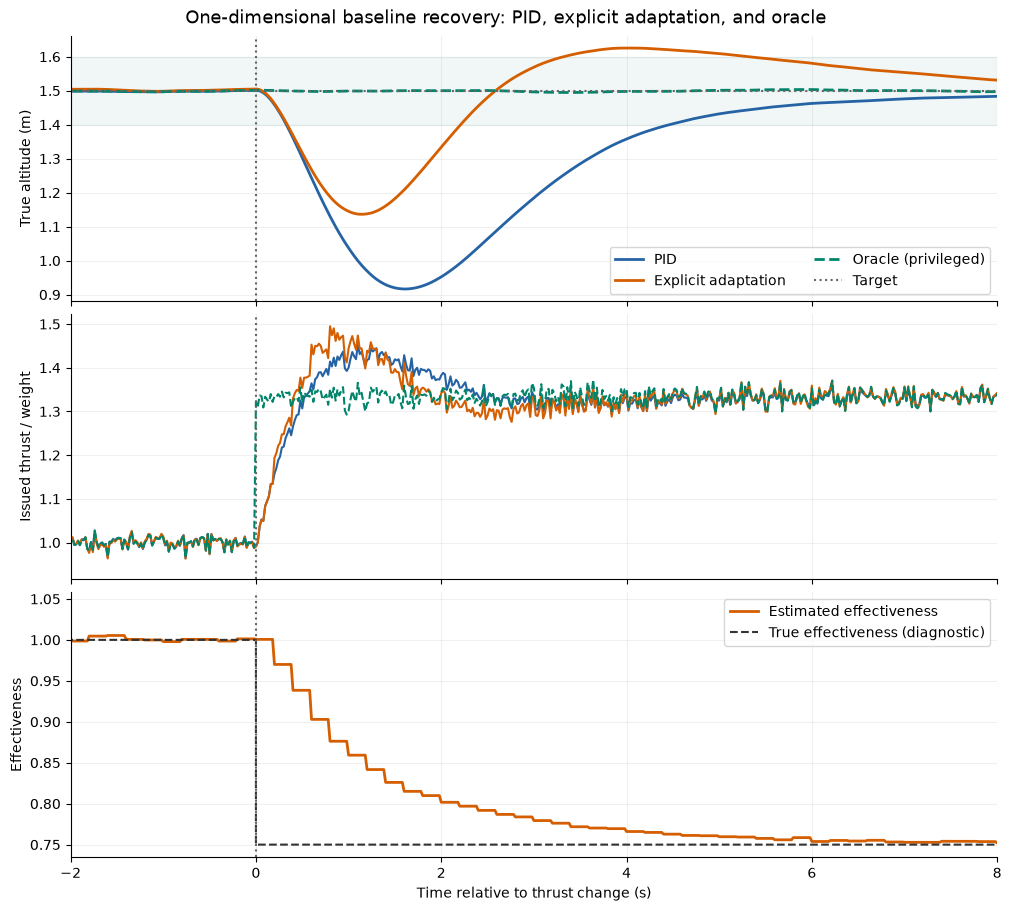

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, constrained_layout=True)
weight = config.mass_kg * config.gravity_m_s2
for method, result in episodes.items():
    rows = result.rows
    time = [row['time_s'] - config.fault_time_s for row in rows]
    linestyle = '--' if method == 'oracle' else '-'
    axes[0].plot(time, [row['z_m'] for row in rows], color=COLORS[method], linestyle=linestyle, label=LABELS[method], linewidth=2)
    # At t, the command applies over the following interval. The terminal row has no command.
    commands = [row for row in rows if row['command_n'] is not None]
    axes[1].plot([row['time_s'] - config.fault_time_s for row in commands], [row['command_n'] / weight for row in commands], color=COLORS[method], linestyle=linestyle)
    if method == 'adaptive':
        axes[2].plot(time, [row['eta_estimate'] for row in rows], color=COLORS[method], label='Estimated effectiveness', linewidth=2)
truth = episodes['pid'].rows
axes[2].step([row['time_s'] - config.fault_time_s for row in truth], [row['eta_true'] for row in truth], where='post', color='#333333', linestyle='--', label='True effectiveness (diagnostic)')
axes[0].axhline(config.target_m, color='#666666', linestyle=':', label='Target')
axes[0].axhspan(config.target_m - 0.1, config.target_m + 0.1, color=COLORS['oracle'], alpha=0.06)
axes[0].set_ylabel('True altitude (m)')
axes[1].set_ylabel('Issued thrust / weight')
axes[2].set_ylabel('Effectiveness')
axes[2].set_xlabel('Time relative to thrust change (s)')
for axis in axes:
    axis.axvline(0, color='#666666', linestyle=':')
    axis.grid(alpha=0.18)
    axis.set_xlim(-2, 8)
axes[0].legend(ncol=2)
axes[2].legend()
fig.suptitle('One-dimensional baseline recovery: PID, explicit adaptation, and oracle', fontsize=13)
plt.show()


## Repeat the comparison across conditions

The next cell recreates the starter matrix: three controllers × three effectiveness levels × two noise levels × five paired evaluation seeds = **90 episodes**. Effectiveness 1.0 is a no-fault control; its scheduled change time is just a scoring anchor.

Fault onsets are sampled with a separate random stream so onset sampling does not shift sensor-noise draws. Seeds vary evaluation scenarios, not independently trained policies. Five episodes per condition are a baseline check, not sufficient evidence for the eventual CNN research question.


In [5]:
effectiveness_levels = [1.0, 0.9, 0.75]
noise_levels = [0.0, 0.01]
evaluation_seeds = list(range(5))
base = ExperimentConfig()
summaries = []
for eta in effectiveness_levels:
    for noise in noise_levels:
        for evaluation_seed in evaluation_seeds:
            # Same independent onset stream as drone_adaptation.run.
            onset = round(random.Random(evaluation_seed + 1_000_003).uniform(3.0, 7.0) / base.dt_s) * base.dt_s
            condition = replace(base, eta_after=eta, noise_z_m=noise, noise_vz_m_s=3 * noise, fault_time_s=onset)
            for method in METHODS:
                summaries.append(run_episode(condition, method, seed=evaluation_seed).summary)
print(f'Completed {len(summaries)} paired baseline episodes.')

def group(eta, noise, method):
    return [row for row in summaries if row['eta_after'] == eta and row['noise_z_m'] == noise and row['method'] == method]

table_rows = []
for eta in effectiveness_levels:
    for noise in noise_levels:
        for method in METHODS:
            rows = group(eta, noise, method)
            table_rows.append([
                f'{100 * (1 - eta):.0f}%', f'{noise:.3f}', LABELS[method],
                f"{sum(row['recovered'] for row in rows)}/{len(rows)}",
                f"{sum(row['failed'] for row in rows)}/{len(rows)}",
                f"{statistics.mean(row['peak_altitude_loss_m'] for row in rows):.3f}",
                f"{statistics.mean(row['capped_recovery_time_s'] for row in rows):.3f}",
            ])
show_table(['Thrust loss', 'Altitude noise SD (m)', 'Controller', 'Recovered', 'Failed', 'Mean peak loss (m)', 'Mean capped recovery (s)'], table_rows)


Completed 90 paired baseline episodes.


Thrust loss,Altitude noise SD (m),Controller,Recovered,Failed,Mean peak loss (m),Mean capped recovery (s)
0%,0.000,PID,5/5,0/5,0.000,0.000
0%,0.000,Explicit adaptation,5/5,0/5,0.000,0.000
0%,0.000,Oracle (privileged),5/5,0/5,0.000,0.000
0%,0.010,PID,5/5,0/5,0.005,0.000
0%,0.010,Explicit adaptation,5/5,0/5,0.006,0.000
0%,0.010,Oracle (privileged),5/5,0/5,0.005,0.000
10%,0.000,PID,5/5,0/5,0.189,3.020
10%,0.000,Explicit adaptation,5/5,0/5,0.130,1.700
10%,0.000,Oracle (privileged),5/5,0/5,0.000,0.000
10%,0.010,PID,5/5,0/5,0.188,3.040


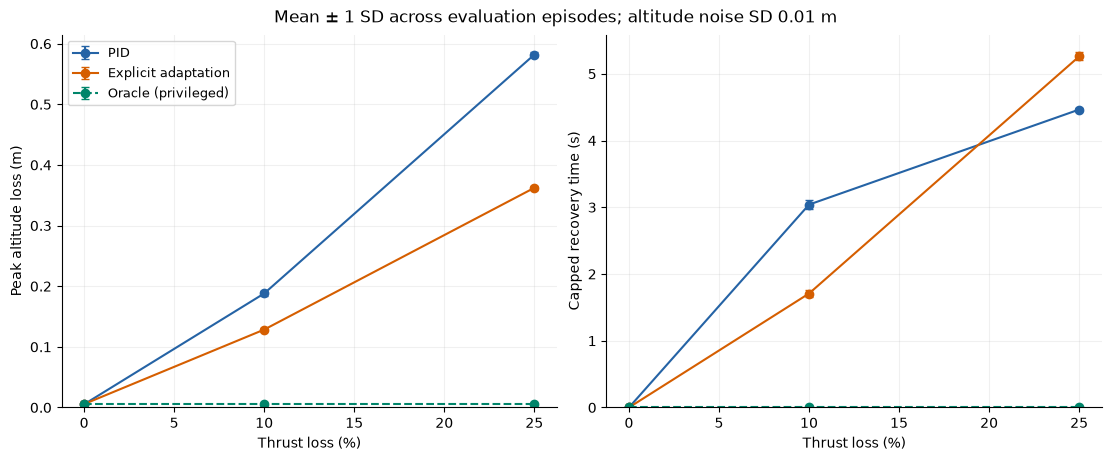

In [6]:
noise_for_plot = max(noise_levels)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
losses = [100 * (1 - eta) for eta in effectiveness_levels]
for method in METHODS:
    for axis, metric in zip(axes, ['peak_altitude_loss_m', 'capped_recovery_time_s']):
        means, deviations = [], []
        for eta in effectiveness_levels:
            values = [row[metric] for row in group(eta, noise_for_plot, method)]
            means.append(statistics.mean(values))
            deviations.append(statistics.stdev(values) if len(values) > 1 else 0.0)
        axis.errorbar(losses, means, yerr=deviations, marker='o', capsize=3, color=COLORS[method], linestyle='--' if method == 'oracle' else '-', label=LABELS[method])
axes[0].set_ylabel('Peak altitude loss (m)')
axes[1].set_ylabel('Capped recovery time (s)')
for axis in axes:
    axis.set_xlabel('Thrust loss (%)')
    axis.set_ylim(bottom=0)
    axis.grid(alpha=0.18)
axes[0].legend(fontsize=9)
fig.suptitle(f'Mean ± 1 SD across evaluation episodes; altitude noise SD {noise_for_plot:g} m', fontsize=12)
plt.show()


In [7]:
comparison_eta = min(effectiveness_levels)
comparison_noise = max(noise_levels)
print(f'Comparison: {100 * (1 - comparison_eta):.0f}% thrust loss, altitude noise SD {comparison_noise:g} m')
pid = group(comparison_eta, comparison_noise, 'pid')
adaptive = group(comparison_eta, comparison_noise, 'adaptive')
for label, rows in [('PID', pid), ('Adaptive', adaptive)]:
    loss = statistics.mean(row['peak_altitude_loss_m'] for row in rows)
    recovery = statistics.mean(row['capped_recovery_time_s'] for row in rows)
    print(f'{label}: average peak altitude loss = {loss:.3f} m; average capped recovery = {recovery:.3f} s')
print('These are fixed-parameter prototype results, not a tuned ranking of controller families.')


Comparison: 25% thrust loss, altitude noise SD 0.01 m
PID: average peak altitude loss = 0.582 m; average capped recovery = 4.464 s
Adaptive: average peak altitude loss = 0.362 m; average capped recovery = 5.260 s
These are fixed-parameter prototype results, not a tuned ranking of controller families.


## What to look for

In the default 25% loss/noisy condition, explicit adaptation reduces the altitude dip but takes longer to settle than PID. Inspect the overshoot, evolving effectiveness estimate, and integral response. A better peak-loss metric does not automatically imply faster recovery. Controller tuning may change the comparison.

To explore another **single scenario**, edit `eta_after`, `noise_z_m`, or `noise_vz_m_s` in the configuration cell and rerun the single-scenario cells. The 90-episode matrix has its own explicit condition lists. Change one factor at a time and ensure sufficient thrust and post-fault evaluation time remain.

Recovery uses true state for scoring. If a flight fails, its shorter RMSE trace is not a fair standalone comparison; retain failure and nonrecovery rates alongside error. The oracle removes uncertainty about effectiveness but still faces observation noise and actuation limits.

### Files behind this notebook

- [Controller and plant implementations](src/drone_adaptation/core.py)
- [Causal experiment loop](src/drone_adaptation/experiment.py)
- [Metric definitions](src/drone_adaptation/metrics.py)
- [Command-line experiment](src/drone_adaptation/run.py)
- [Portable altitude experiment guide](README.md)

The next project stage is to establish the same baseline in a full drone simulator, add a bounded learned residual, and then investigate history duration under held-out changes. This notebook provides the baseline, not evidence that a particular CNN history length is best.
